# Анализ экспериментов MLflow

Стадия train (src/models/train.py) обучает пять алгоритмов, подбирает им гиперпараметры через RandomizedSearchCV и порог по F1 и пишет каждый в MLflow отдельным запуском. Здесь сравниваем запуски и проверяем лучшую модель на тестовой выборке.

## 1. Импорты

Модель содержит функцию признаков из src, поэтому добавляем корень репозитория в sys.path.

In [1]:
import json
import sys

import joblib
import matplotlib.pyplot as plt
import mlflow
import pandas as pd
import sklearn.metrics

sys.path.append("..")
import src.features.build_features as build_features

plt.rcParams.update({
    "figure.facecolor": "none",
    "axes.facecolor": "none",
    "text.color": "gray",
    "axes.labelcolor": "gray",
    "axes.edgecolor": "gray",
    "xtick.color": "gray",
    "ytick.color": "gray"
})

## 2. Загрузка запусков

Новые запуски появляются, когда dvc repro перезапускает обучение, поэтому для каждого алгоритма берём последний.

In [2]:
mlflow.set_tracking_uri("sqlite:///../mlflow.db")
runs = mlflow.search_runs(experiment_names=["credit_default_prediction"], order_by=["start_time DESC"])
runs = runs.drop_duplicates("params.model_type")
print("Запусков в эксперименте:", len(mlflow.search_runs(experiment_names=["credit_default_prediction"])))
print("Алгоритмов:", len(runs))

Запусков в эксперименте: 5
Алгоритмов: 5


5 запусков, по одному на алгоритм: логистическая регрессия, случайный лес, extra trees, градиентный бустинг и HistGradientBoosting.

## 3. Сравнение моделей

Собираем ROC-AUC на кросс-валидации и метрики на тесте в одну таблицу.

In [3]:
metric_columns = ["cv_roc_auc", "test_roc_auc", "test_precision", "test_recall", "test_f1", "threshold"]
comparison = runs.set_index("params.model_type")[[f"metrics.{name}" for name in metric_columns]]
comparison.columns = metric_columns
comparison.index.name = "model"
comparison = comparison.sort_values("cv_roc_auc", ascending=False)
comparison.round(4)

,cv_roc_auc,test_roc_auc,test_precision,test_recall,test_f1,threshold
model,,,,,,
random_forest,0.7859,0.7795,0.5295,0.5539,0.5414,0.5813
hist_gradient_boosting,0.7851,0.7795,0.5160,0.5599,0.5370,0.2902
gradient_boosting,0.7842,0.7854,0.5306,0.5622,0.5459,0.2868
extra_trees,0.7827,0.7752,0.5221,0.5433,0.5325,0.2827
logistic_regression,0.7601,0.7471,0.4747,0.5592,0.5135,0.5586


По ROC-AUC на кросс-валидации лучший случайный лес (0.7859), остальные ансамбли отстают меньше чем на 0.004, логистическая регрессия — на 0.026. На тесте немного лучше градиентный бустинг, но по тесту модель не выбираем, иначе он перестанет быть независимой проверкой.

Сравниваем ROC-AUC на кросс-валидации и на тесте, чтобы проверить переобучение.

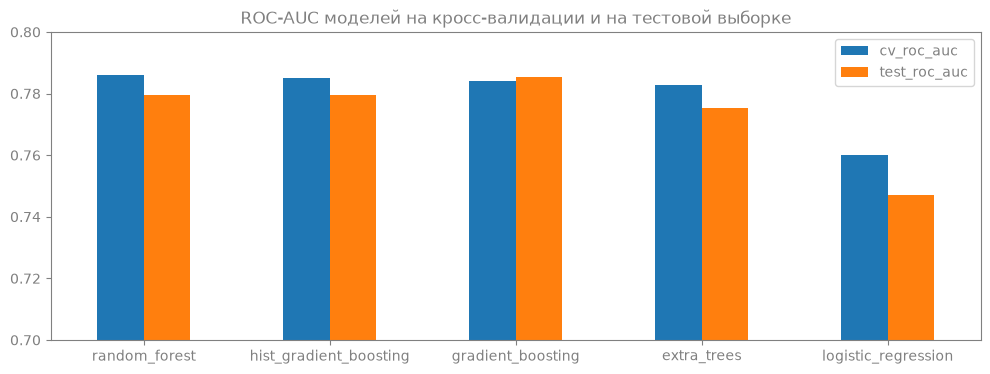

,cv - test
model,
random_forest,0.0064
hist_gradient_boosting,0.0057
gradient_boosting,-0.0013
extra_trees,0.0075
logistic_regression,0.0130


In [4]:
fig, ax = plt.subplots(figsize=(12, 4))
comparison[["cv_roc_auc", "test_roc_auc"]].plot.bar(ax=ax, rot=0)
ax.set_ylim(0.7, 0.8)
ax.set_title("ROC-AUC моделей на кросс-валидации и на тестовой выборке")
ax.set_xlabel("")
plt.show()
(comparison["cv_roc_auc"] - comparison["test_roc_auc"]).round(4).to_frame("cv - test")

Разница между кросс-валидацией и тестом не больше 0.013, переобучения нет, порядок моделей почти тот же.

## 4. Гиперпараметры

Выводим подобранные гиперпараметры. Параметры, которые алгоритм не перебирал, показаны как NaN.

In [5]:
param_columns = [c for c in runs.columns if c.startswith("params.") and c not in ("params.model_type", "params.cv", "params.n_iter")]
runs.set_index("params.model_type")[param_columns].rename(columns=lambda c: c.removeprefix("params.")).T

params.model_type,hist_gradient_boosting,gradient_boosting,extra_trees,random_forest,logistic_regression
learning_rate,0.1,0.03,NaN,NaN,NaN
max_iter,400,NaN,NaN,NaN,NaN
l2_regularization,10.0,NaN,NaN,NaN,NaN
max_leaf_nodes,31,NaN,NaN,NaN,NaN
min_samples_leaf,50,NaN,20,20,NaN
n_estimators,NaN,300,NaN,NaN,NaN
max_depth,NaN,4,15,10,NaN
subsample,NaN,1.0,NaN,NaN,NaN
class_weight,NaN,NaN,None,balanced,balanced
max_features,NaN,NaN,0.5,sqrt,NaN


Случайный лес и логистическая регрессия выбрали взвешивание классов class_weight=balanced, поэтому их вероятности сдвинуты вверх и подобранный порог выше 0.5.

## 5. Проверка лучшей модели

Загружаем модель из models/ и метрики из metrics.json.

In [6]:
model = joblib.load("../models/credit_default_model.pkl")
test = pd.read_csv("../data/processed/test.csv")
X_test, y_test = test[build_features.INPUT_FEATURES], test["default"]
with open("../metrics.json") as f:
    summary = json.load(f)
summary

{'model': 'random_forest',
 'run_id': 'c6585a787bab420aa0b219e015d8f423',
 'cv_roc_auc': 0.7859071425137465,
 'test_roc_auc': 0.7794880916538449,
 'test_precision': 0.5295389048991355,
 'test_recall': 0.5538809344385832,
 'test_f1': 0.5414364640883977}

Строим ROC-кривую на тестовой выборке.

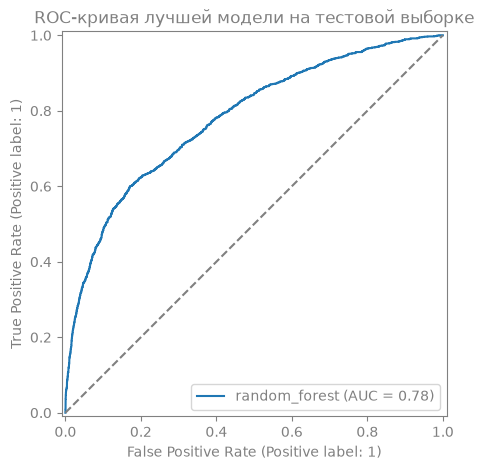

In [7]:
y_proba = model.predict_proba(X_test)[:, 1]
fig, ax = plt.subplots(figsize=(6, 5))
sklearn.metrics.RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax, name=summary["model"])
ax.plot([0, 1], [0, 1], linestyle="--", color="grey")
ax.set_title("ROC-кривая лучшей модели на тестовой выборке")
plt.show()

Площадь под кривой 0.7795, как test_roc_auc в MLflow, то есть в models/ та же модель.

Сравниваем матрицу ошибок при подобранном пороге и при 0.5.

In [8]:
y_pred = model.predict(X_test)
y_pred_05 = (y_proba >= 0.5).astype(int)
print("Порог:", round(model.best_threshold_, 3))
print(pd.DataFrame(sklearn.metrics.confusion_matrix(y_test, y_pred), index=["факт 0", "факт 1"], columns=["прогноз 0", "прогноз 1"]))
pd.DataFrame(
    {
        "подобранный порог": [sklearn.metrics.precision_score(y_test, y_pred), sklearn.metrics.recall_score(y_test, y_pred), sklearn.metrics.f1_score(y_test, y_pred)],
        "порог 0.5": [sklearn.metrics.precision_score(y_test, y_pred_05), sklearn.metrics.recall_score(y_test, y_pred_05), sklearn.metrics.f1_score(y_test, y_pred_05)]
    },
    index=["precision", "recall", "f1"]
).round(4)

Порог: 0.581
        прогноз 0  прогноз 1
факт 0       4020        653
факт 1        592        735


,подобранный порог,порог 0.5
precision,0.5295,0.4678
recall,0.5539,0.6247
f1,0.5414,0.5350


При пороге 0.581 модель находит 735 из 1327 дефолтов (recall 0.5539) и ошибочно отмечает 653 клиента без дефолта. При пороге 0.5 recall 0.6247, precision 0.4678, F1 0.535 против 0.5414.

## 6. Выводы

1. Провели 5 экспериментов с разными алгоритмами, в каждом RandomizedSearchCV перебирал 10 наборов гиперпараметров на 3-кратной кросс-валидации. В MLflow записаны параметры, метрики, ROC-кривая, cv_results и модель.
2. Лучшая по ROC-AUC на кросс-валидации — случайный лес (0.7859), остальные ансамбли отстают меньше чем на 0.004, логистическая регрессия — на 0.026.
3. На тесте лучшая модель даёт ROC-AUC 0.7795, precision 0.5295, recall 0.5539, F1 0.5414.
4. Подбор порога по F1 дал порог 0.581 и F1 0.5414 против 0.535 при пороге 0.5.